# Figure 2c–e — cross-validation performance

Three panels, one input directory. Everything is read from `raw_data/`, the Source Data submitted with the paper. Download
it from the Zenodo record linked in the repository README and unpack it at the repository
root, so `raw_data/` sits next to `smartbind/`; the notebook walks up to find it.:

| panel | what it draws | source table |
|---|---|---|
| **2c** | box plots of the per-complex rank percentile on the HARIBOSS 5-fold **RNA sequence-based** split, seven models | `Fig2c_rank_percentile_per_sample.csv` |
| **2d** | grouped bars, fold-wise mean ± s.d. under four further splitting strategies | `Fig2d_rank_percentile_per_fold.csv` |
| **2e** | mirrored bars, SMARTBind vs GerNA-Bind on the 168-complex GerNA-Bind subset | `Fig2e_rank_percentile_per_fold.csv` |

Each panel also ships a `*_summary.csv` holding exactly what the published panel drew on top of
the points: box statistics, bar heights, error bars, p-values. The last cell recomputes all of
them from the per-point tables and asserts they agree, so a change to either file is caught
rather than silently plotted.

**No model weights and no inference are needed.** The SMARTBind values in these tables were
produced by the cross-validation inference run from the Zenodo 5-fold datasets and the released
cross-validation checkpoints. The last cell of this notebook re-derives every plotted value
from the per-point tables and asserts it against the shipped summaries.

In [1]:

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.stats import mannwhitneyu

# Locate the Source Data.  Download `raw_data` from the link named in the
# repository README and unpack it at the repository root; this walks up to find it, so
# the notebook runs from anywhere inside the checkout.
from pathlib import Path


def find_raw_data():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "raw_data"
        if candidate.is_dir():
            return candidate
    raise SystemExit(
        "\nCould not find `raw_data/`.\n\n"
        "The raw data is not provided with the release. Reproduce the underlying\n"
        "numbers with the inference scripts.\n")


RAW = find_raw_data()
SRC = RAW / "Fig2"
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

# The palette the published figures use, keyed by model.
MODEL_COLORS = {
    "SMARTBind": "#64599C",
    "RNAmigos1": "#F4E9B3",
    "RNAmigos2": "#E2B668",
    "RNAsmol": "#5B789E",
    "GerNA-Bind": "#AEB2D0",
    "DrugBAN_RNA": "#C9A0A0",
    "GraphDTA_RNA": "#7FA99B",
    "AutoDock-GPU": "#E8927C",
    "rDock": "#A3C4BC",
}

fig2c = pd.read_csv(SRC / "Fig2c_rank_percentile_per_sample.csv")
fig2c_summary = pd.read_csv(SRC / "Fig2c_summary.csv")
fig2d = pd.read_csv(SRC / "Fig2d_rank_percentile_per_fold.csv")
fig2d_summary = pd.read_csv(SRC / "Fig2d_summary.csv")
fig2e = pd.read_csv(SRC / "Fig2e_rank_percentile_per_fold.csv")
fig2e_summary = pd.read_csv(SRC / "Fig2e_summary.csv")


def stars(p):
    """The convention printed in the Fig. 2 caption."""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


for name, table in [("2c", fig2c), ("2d", fig2d), ("2e", fig2e)]:
    print(f"Fig {name}: {len(table):,} rows, {table.model.nunique()} models")

Fig 2c: 7,278 rows, 7 models
Fig 2d: 100 rows, 5 models
Fig 2e: 50 rows, 2 models


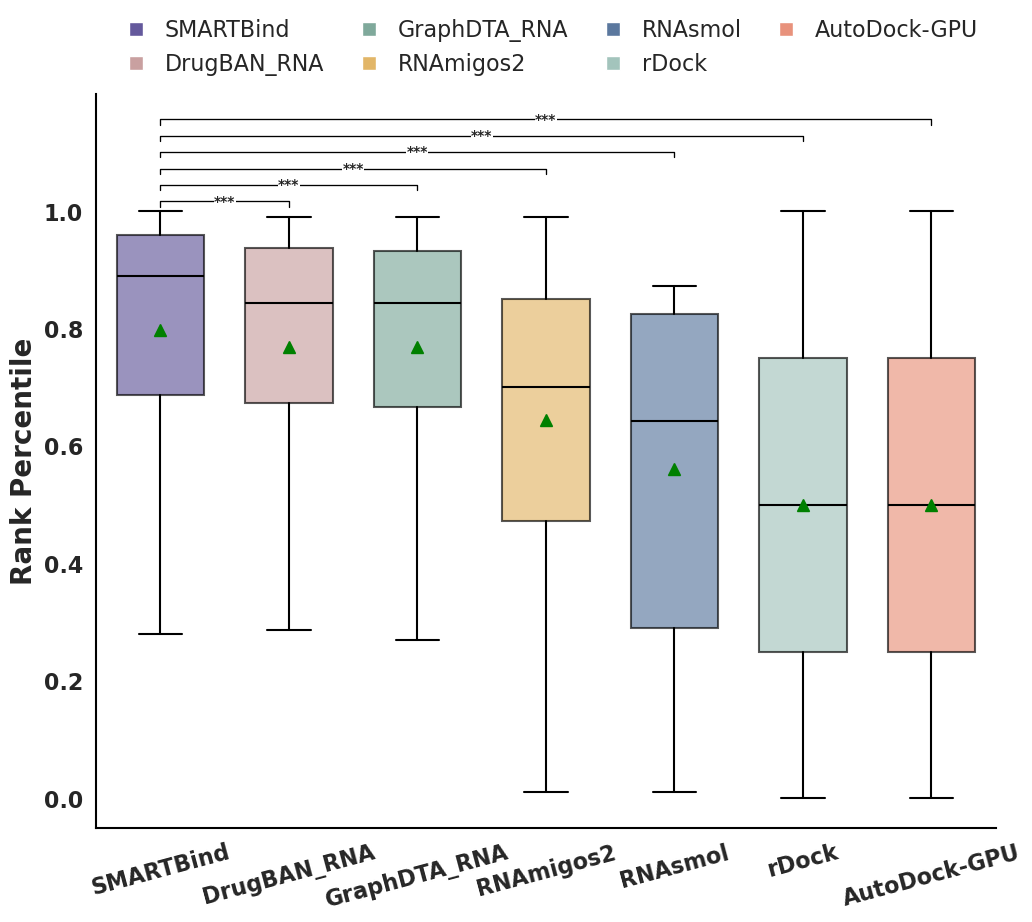

  SMARTBind      n= 1246  mean 0.7971  median 0.8906
  DrugBAN_RNA    n= 1239  mean 0.7696  median 0.8438   vs SMARTBind ***
  GraphDTA_RNA   n= 1237  mean 0.7682  median 0.8444   vs SMARTBind ***
  RNAmigos2      n= 1220  mean 0.6444  median 0.7000   vs SMARTBind ***
  RNAsmol        n= 1109  mean 0.5609  median 0.6429   vs SMARTBind ***
  rDock          n=  594  mean 0.5000  median 0.5000   vs SMARTBind ***
  AutoDock-GPU   n=  633  mean 0.4999  median 0.5000   vs SMARTBind ***


In [2]:
# ── Fig. 2c — RNA sequence-based split, per-complex rank percentile ────────────
# Models are ordered by descending mean, which is the order the published panel uses.
model_order = (fig2c.groupby("model").rank_percentile.mean()
               .sort_values(ascending=False).index.tolist())
scores = {m: fig2c.loc[fig2c.model == m, "rank_percentile"].values for m in model_order}

# One-tailed Wilcoxon rank-sum, SMARTBind > model, recomputed from the plotted points.
sig = {m: stars(mannwhitneyu(scores["SMARTBind"], scores[m], alternative="greater")[1])
       for m in model_order if m != "SMARTBind"}

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(10.5, 9.3))

for i, model in enumerate(model_order):
    ax.boxplot(
        [scores[model]], positions=[i], widths=0.68,
        patch_artist=True, showmeans=True, showfliers=False,
        meanprops={"marker": "^", "markerfacecolor": "green",
                   "markeredgecolor": "green", "markersize": 8},
        medianprops={"color": "black", "linewidth": 1.5},
        boxprops={"facecolor": MODEL_COLORS[model], "edgecolor": "black",
                  "linewidth": 1.5, "alpha": 0.65},
        whiskerprops={"color": "black", "linewidth": 1.5},
        capprops={"color": "black", "linewidth": 1.5},
    )

ax.legend(
    handles=[Line2D([0], [0], marker="s", color="w", markerfacecolor=MODEL_COLORS[m],
                    markersize=10, label=m) for m in model_order],
    fontsize=16, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.13),
    ncol=int(np.ceil(len(model_order) / 2)), columnspacing=1, handletextpad=0.3,
)

ax.set_xlabel("")
ax.set_ylabel("Rank Percentile", fontsize=20, fontweight="bold")
ax.set_xticks(range(len(model_order)))
ax.set_xticklabels(model_order)
ax.set_xlim(-0.5, len(model_order) - 0.5)
ax.tick_params(axis="both", labelsize=16, width=2, length=6)
for label in ax.get_xticklabels():
    label.set_fontweight("bold")
    label.set_fontsize(16)
    label.set_rotation(15)
for label in ax.get_yticklabels():
    label.set_fontweight("bold")
for side, on in [("top", False), ("right", False), ("left", True), ("bottom", True)]:
    ax.spines[side].set_visible(on)
    if on:
        ax.spines[side].set_linewidth(1.5)
        ax.spines[side].set_color("black")
ax.grid(False)

# Significance brackets, shortest span first so they stack without crossing.
smartbind_idx = model_order.index("SMARTBind")
y_max = fig2c.rank_percentile.max()
height, step = 0.018, 0.028
current = y_max + 0.008
for idx, model in sorted(
        [(i, m) for i, m in enumerate(model_order) if m != "SMARTBind"],
        key=lambda t: abs(t[0] - smartbind_idx)):
    ax.plot([smartbind_idx, smartbind_idx, idx, idx],
            [current, current + height / 2, current + height / 2, current],
            color="black", linewidth=0.95)
    ax.text((smartbind_idx + idx) / 2, current + height / 2, sig[model],
            ha="center", va="center", fontsize=10,
            fontweight="bold" if sig[model] != "n.s." else "normal",
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.16}, zorder=5)
    current += step

ax.set_ylim(fig2c.rank_percentile.min() - 0.05, y_max + 0.20)
ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

plt.tight_layout()
plt.savefig(OUT / "Fig2c_sequence_split_boxplot.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig2c_sequence_split_boxplot.png", bbox_inches="tight", dpi=600)
plt.show()

for model in model_order:
    v = scores[model]
    print(f"  {model:<14} n={len(v):>5}  mean {v.mean():.4f}  median {np.median(v):.4f}"
          + ("" if model == "SMARTBind" else f"   vs SMARTBind {sig[model]}"))

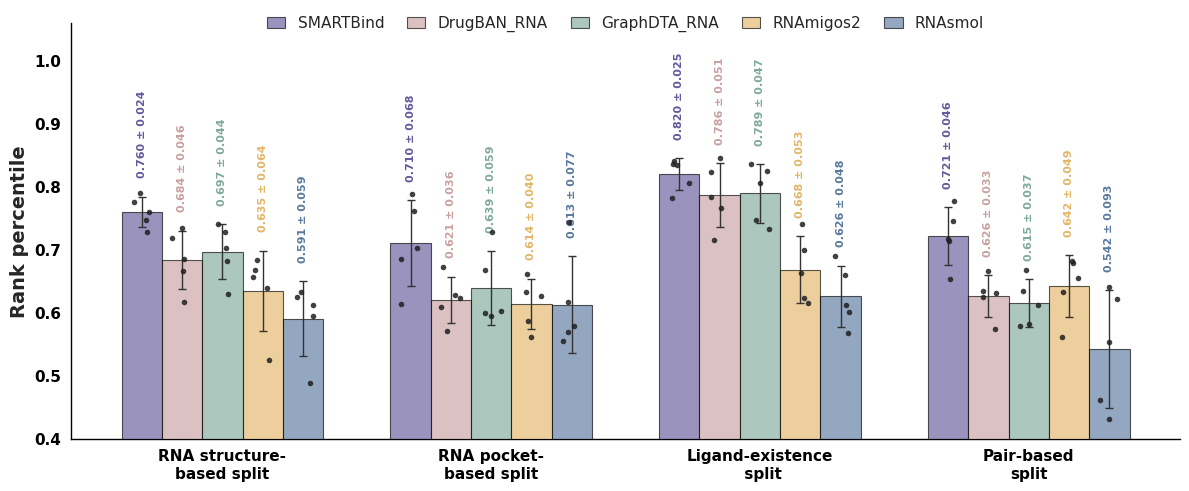

  RNA structure- based split   SMARTBind 0.760 ± 0.024   second-best GraphDTA_RNA 0.697 ± 0.044
  RNA pocket- based split      SMARTBind 0.710 ± 0.068   second-best GraphDTA_RNA 0.639 ± 0.059
  Ligand-existence  split      SMARTBind 0.820 ± 0.025   second-best GraphDTA_RNA 0.789 ± 0.047
  Pair-based split             SMARTBind 0.721 ± 0.046   second-best RNAmigos2 0.642 ± 0.049


In [3]:
# ── Fig. 2d — four further splitting strategies, fold-wise mean ± s.d. ────────
SPLIT_ORDER_2D = ["chainStructure", "pocketStructure", "ligandExist", "pairSplit"]
SPLIT_TITLES_2D = ["RNA structure-\nbased split", "RNA pocket-\nbased split",
                   "Ligand-existence\n split", "Pair-based\nsplit"]
MODEL_ORDER_2D = ["SMARTBind", "DrugBAN_RNA", "GraphDTA_RNA", "RNAmigos2", "RNAsmol"]

folds = {(m, s): fig2d.loc[(fig2d.model == m) & (fig2d.split == s), "rank_percentile"].values
         for m in MODEL_ORDER_2D for s in SPLIT_ORDER_2D}
means = np.array([[folds[(m, s)].mean() for s in SPLIT_ORDER_2D] for m in MODEL_ORDER_2D])
stds = np.array([[folds[(m, s)].std(ddof=1) for s in SPLIT_ORDER_2D] for m in MODEL_ORDER_2D])

fig, ax = plt.subplots(figsize=(12, 5.0))
bar_width = 0.15
x = np.arange(len(SPLIT_ORDER_2D))
n_models = len(MODEL_ORDER_2D)

for i, model in enumerate(MODEL_ORDER_2D):
    offset = (i - n_models / 2 + 0.5) * bar_width
    color = MODEL_COLORS[model]
    ax.bar(x + offset, means[i], bar_width, yerr=stds[i], label=model, color=color,
           alpha=0.65, edgecolor="black", linewidth=0.8, capsize=3,
           error_kw=dict(lw=1, capthick=1, ecolor="#333333"), zorder=3)
    for j, split in enumerate(SPLIT_ORDER_2D):
        vals = folds[(model, split)]
        # deterministic jitter, so re-running the notebook redraws the same dots
        jitter = np.random.default_rng(42 + i * 10 + j).uniform(
            -bar_width * 0.25, bar_width * 0.25, len(vals))
        ax.scatter(np.full(len(vals), x[j] + offset) + jitter, vals,
                   color="#1f1f1f", s=16, zorder=4, alpha=0.85, linewidths=0)
        ax.text(x[j] + offset, means[i, j] + stds[i, j] + 0.03,
                f"{means[i, j]:.3f} ± {stds[i, j]:.3f}", ha="center", va="bottom",
                fontsize=8, color=color, fontweight="bold", rotation=90)

ax.set_ylabel("Rank percentile", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(SPLIT_TITLES_2D, fontsize=11, fontweight="bold")
ax.set_ylim(0.4, 1.06)
ax.set_yticks(np.arange(0.4, 1.01, 0.1))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.05), ncol=n_models,
          frameon=False, fontsize=11, handlelength=1.2, columnspacing=1.5)
ax.grid(False)
for side, on in [("top", False), ("right", False), ("left", True), ("bottom", True)]:
    ax.spines[side].set_visible(on)
    if on:
        ax.spines[side].set_linewidth(1.0)
        ax.spines[side].set_color("black")
ax.tick_params(axis="x", labelsize=11, colors="black")
ax.tick_params(axis="y", labelsize=11, colors="black")
for label in ax.get_yticklabels():
    label.set_fontweight("bold")

plt.tight_layout()
plt.savefig(OUT / "Fig2d_splitting_performance_barplot.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig2d_splitting_performance_barplot.png", bbox_inches="tight", dpi=600)
plt.show()

for j, split in enumerate(SPLIT_ORDER_2D):
    best = max(range(n_models), key=lambda i: means[i, j])
    second = max((i for i in range(n_models) if i != best), key=lambda i: means[i, j])
    print(f"  {SPLIT_TITLES_2D[j].replace(chr(10), ' '):<28} "
          f"{MODEL_ORDER_2D[best]} {means[best, j]:.3f} ± {stds[best, j]:.3f}   "
          f"second-best {MODEL_ORDER_2D[second]} {means[second, j]:.3f} ± {stds[second, j]:.3f}")

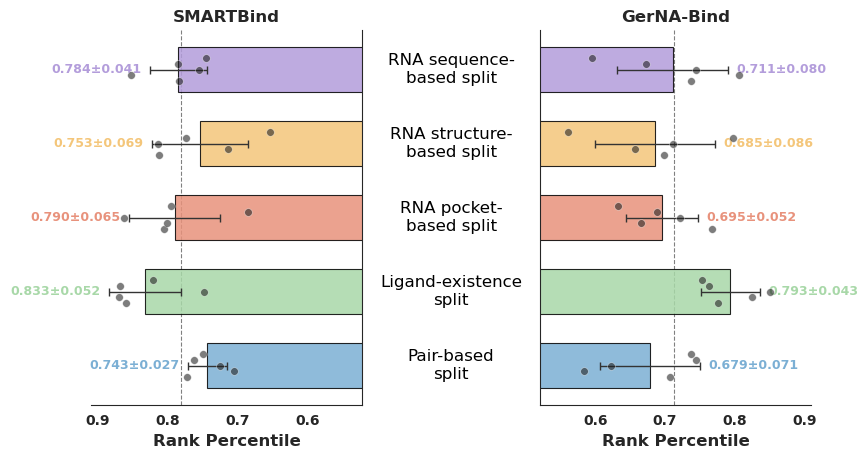

  sequenceSplit      SMARTBind 0.7842 ± 0.0413   GerNA-Bind 0.7108 ± 0.0798
  chainStructure     SMARTBind 0.7534 ± 0.0690   GerNA-Bind 0.6853 ± 0.0860
  pocketStructure    SMARTBind 0.7896 ± 0.0650   GerNA-Bind 0.6951 ± 0.0516
  ligandExist        SMARTBind 0.8326 ± 0.0516   GerNA-Bind 0.7933 ± 0.0425
  pairSplit          SMARTBind 0.7427 ± 0.0274   GerNA-Bind 0.6789 ± 0.0713


In [4]:
# ── Fig. 2e — GerNA-Bind subset (n = 168), SMARTBind vs GerNA-Bind ───────────
SPLIT_ORDER_2E = ["sequenceSplit", "chainStructure", "pocketStructure",
                  "ligandExist", "pairSplit"]
SPLIT_TITLES_2E = ["RNA sequence-\nbased split", "RNA structure-\nbased split",
                   "RNA pocket-\nbased split", "Ligand-existence\nsplit",
                   "Pair-based\nsplit"]
BAR_COLORS = ["#B39DDB", "#F4C67A", "#E8927C", "#A8D8A8", "#7BAFD4"]


def mirror_bars(table, value_col, axis_label, out_stem,
                left_model="SMARTBind", right_model="GerNA-Bind",
                split_col="split", split_order=SPLIT_ORDER_2E,
                split_titles=SPLIT_TITLES_2E):
    """The two-sided bar chart of Fig. 2e / Supplementary Fig. 4b.

    One row per split; the left half is `left_model`, the right half `right_model`,
    bars are the mean over the folds with an s.d. error bar and the five fold
    values overlaid as dots.
    """
    per_model = {}
    for model in (left_model, right_model):
        vals = [table.loc[(table.model == model) & (table[split_col] == s), value_col].values
                for s in split_order]
        per_model[model] = {
            "vals": vals,
            "means": [v.mean() for v in vals],
            "stds": [v.std(ddof=1) for v in vals],
        }

    pooled = np.concatenate([v for m in per_model.values() for v in m["vals"]])
    x_min, x_max = max(0.4, pooled.min() - 0.04), min(1.0, pooled.max() + 0.04)

    sns.set_style("white")
    fig = plt.figure(figsize=(8.0, 4.8))
    gs = gridspec.GridSpec(1, 3, width_ratios=[4.2, 2.4, 4.2], wspace=0.05)
    ax_left = fig.add_subplot(gs[0])
    ax_mid = fig.add_subplot(gs[1], sharey=ax_left)
    ax_right = fig.add_subplot(gs[2], sharey=ax_left)

    y = np.arange(len(split_order))[::-1]
    point_offsets = np.linspace(-0.16, 0.16, 5)

    for ax, model, flip in [(ax_left, left_model, True), (ax_right, right_model, False)]:
        stats = per_model[model]
        for i in range(len(split_order)):
            ax.barh(y[i], stats["means"][i], height=0.6, color=BAR_COLORS[i],
                    edgecolor="black", linewidth=0.8, zorder=2, alpha=0.85)
            ax.errorbar(stats["means"][i], y[i], xerr=stats["stds"][i], fmt="none",
                        ecolor="#333", capsize=3, capthick=1, lw=1, zorder=3)
            text_x = min(x_max - 0.004, stats["means"][i] + stats["stds"][i] + 0.012)
            ax.text(text_x, y[i], f"{stats['means'][i]:.3f}±{stats['stds'][i]:.3f}",
                    ha="right" if flip else "left", va="center",
                    fontsize=9, fontweight="bold", color=BAR_COLORS[i])
            vals = stats["vals"][i]
            ax.scatter(vals, np.full(len(vals), y[i], dtype=float) + point_offsets[:len(vals)],
                       s=30, color="#1f1f1f", edgecolors="white", linewidths=0.4,
                       alpha=0.58, zorder=4)
        ax.set_xlim((x_max, x_min) if flip else (x_min, x_max))
        ax.set_xlabel(axis_label, fontsize=12, fontweight="bold")
        ax.set_title(model, fontsize=12, fontweight="bold")
        ax.axvline(x=np.mean(stats["means"]), color="grey", ls="--", lw=0.8, zorder=1)
        ax.spines["top"].set_visible(False)
        ax.spines["left" if flip else "right"].set_visible(False)
        ax.set_yticks(y)
        ax.set_yticklabels([""] * len(split_order))
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=10)
        for label in ax.get_xticklabels():
            label.set_fontweight("bold")

    ax_mid.set_xlim(0, 1)
    ax_mid.set_ylim(ax_left.get_ylim())
    for i, title in enumerate(split_titles):
        ax_mid.text(0.5, y[i], title, ha="center", va="center", fontsize=12,
                    color="black", linespacing=1.2,
                    bbox={"facecolor": "white", "edgecolor": "none",
                          "pad": 1.5, "alpha": 0.95})
    ax_mid.axis("off")

    fig.subplots_adjust(left=0.06, right=0.96, top=0.92, bottom=0.14, wspace=0.05)
    plt.savefig(OUT / f"{out_stem}.pdf", bbox_inches="tight", dpi=300)
    plt.savefig(OUT / f"{out_stem}.png", bbox_inches="tight", dpi=600)
    plt.show()

    for i, s in enumerate(split_order):
        print(f"  {s:<18} {left_model} {per_model[left_model]['means'][i]:.4f}"
              f" ± {per_model[left_model]['stds'][i]:.4f}"
              f"   {right_model} {per_model[right_model]['means'][i]:.4f}"
              f" ± {per_model[right_model]['stds'][i]:.4f}")
    return per_model


_ = mirror_bars(fig2e, "rank_percentile", "Rank Percentile",
                "Fig2e_gbsubset_mirror_rank_percentile")

In [5]:
# ── Self-check: everything the panels draw, recomputed from the per-point tables ──
# The shipped *_summary.csv files are what the published panels drew.  If a source
# table is ever edited, this cell fails instead of the figure changing silently.
failures = []


def compare(label, got, want, tol=5e-4):
    ok = abs(float(got) - float(want)) <= tol
    if not ok:
        failures.append(f"{label}: recomputed {got:.6f} vs shipped {want:.6f}")
    return ok


print("Fig. 2c: box statistics")
for _, row in fig2c_summary.iterrows():
    v = scores[row.model]
    q1, q3 = np.percentile(v, [25, 75])
    whisker_lo = v[v >= q1 - 1.5 * (q3 - q1)].min()
    whisker_hi = v[v <= q3 + 1.5 * (q3 - q1)].max()
    checks = [
        compare(f"2c {row.model} n", len(v), row.n_samples, 0),
        compare(f"2c {row.model} mean", v.mean(), row.plotted_mean_green_triangle),
        compare(f"2c {row.model} median", np.median(v), row.median_box_centre_line),
        compare(f"2c {row.model} q1", q1, row.q1_box_lower),
        compare(f"2c {row.model} q3", q3, row.q3_box_upper),
        compare(f"2c {row.model} whisker_low", whisker_lo, row.whisker_low),
        compare(f"2c {row.model} whisker_high", whisker_hi, row.whisker_high),
        compare(f"2c {row.model} sd", v.std(ddof=1), row.sd_rank_percentile),
    ]
    note = ""
    if row.model != "SMARTBind":
        # The tables are rounded to 4 dp, which adds ties, so the recomputed p-value
        # differs from the shipped one in the third digit.  The star must still match.
        note = f"  p {sig[row.model]} (shipped {row.significance})"
        if sig[row.model] != row.significance:
            failures.append(f"2c {row.model}: star {sig[row.model]} vs {row.significance}")
    print(f"  {row.model:<14} {'ok' if all(checks) else 'MISMATCH'}{note}")

print("\nFig. 2d: bar heights and error bars")
for _, row in fig2d_summary.iterrows():
    v = folds[(row.model, row.split)]
    ok = all([compare(f"2d {row.split}/{row.model} n", len(v), row.n_folds, 0),
              compare(f"2d {row.split}/{row.model} mean", v.mean(), row.plotted_bar_height),
              compare(f"2d {row.split}/{row.model} sd", v.std(ddof=1), row.plotted_error_bar)])
    print(f"  {row.split:<16} {row.model:<14} {'ok' if ok else 'MISMATCH'}")

print("\nFig. 2e: bar lengths and error bars")
for _, row in fig2e_summary.iterrows():
    v = fig2e.loc[(fig2e.model == row.model) & (fig2e.split == row.split),
                  "rank_percentile"].values
    ok = all([compare(f"2e {row.split}/{row.model} n", len(v), row.n_folds, 0),
              compare(f"2e {row.split}/{row.model} mean", v.mean(), row.plotted_bar_length),
              compare(f"2e {row.split}/{row.model} sd", v.std(ddof=1), row.plotted_error_bar)])
    print(f"  {row.split:<16} {row.model:<12} {'ok' if ok else 'MISMATCH'}")

print()
if failures:
    for f in failures:
        print("  " + f)
    raise AssertionError(f"{len(failures)} value(s) do not reproduce the shipped summary")
print(f"PASS: every plotted value reproduces the shipped summary tables "
      f"({len(fig2c_summary) * 8 + len(fig2d_summary) * 3 + len(fig2e_summary) * 3} checks)")

Fig. 2c — box statistics
  SMARTBind      ok
  DrugBAN_RNA    ok  p *** (shipped ***)
  GraphDTA_RNA   ok  p *** (shipped ***)
  RNAmigos2      ok  p *** (shipped ***)
  RNAsmol        ok  p *** (shipped ***)
  rDock          ok  p *** (shipped ***)
  AutoDock-GPU   ok  p *** (shipped ***)

Fig. 2d — bar heights and error bars
  chainStructure   SMARTBind      ok
  chainStructure   DrugBAN_RNA    ok
  chainStructure   GraphDTA_RNA   ok
  chainStructure   RNAmigos2      ok
  chainStructure   RNAsmol        ok
  pocketStructure  SMARTBind      ok
  pocketStructure  DrugBAN_RNA    ok
  pocketStructure  GraphDTA_RNA   ok
  pocketStructure  RNAmigos2      ok
  pocketStructure  RNAsmol        ok
  ligandExist      SMARTBind      ok
  ligandExist      DrugBAN_RNA    ok
  ligandExist      GraphDTA_RNA   ok
  ligandExist      RNAmigos2      ok
  ligandExist      RNAsmol        ok
  pairSplit        SMARTBind      ok
  pairSplit        DrugBAN_RNA    ok
  pairSplit        GraphDTA_RNA   ok
  pai